# Scalar autograd: from computation to gradients

See how `Value` builds a graph, why each operation has its own `_backward`, and how `backward()` finds gradients. Example: **loss = (x · w + b)²**, where `x = 2`, `w = 3`, and `b = 1`.

Run the cells from top to bottom. Install the `notebook` dependency group with `uv sync --group notebook`, then run `uv run --group notebook jupyter lab` from the project root.

## 1. Setup

The notebook imports the actual `Value` class from the project. It can be run from either the project root or the `examples` directory.

In [1]:
from pathlib import Path
import sys
from html import escape
from IPython.display import SVG, display

cwd = Path.cwd().resolve()
root = cwd if (cwd / "src" / "tinytorch").is_dir() else cwd.parent
if not (root / "src" / "tinytorch").is_dir():
    raise RuntimeError("Run the notebook from the project root or the examples directory")
sys.path.insert(0, str(root / "src"))
from tinytorch.autograd import Value

## 2. Forward pass

Each result is a `Value`. It holds a number, links to the operation's inputs in `prev`, and a saved `_backward` callback.

In [2]:
x = Value(2.0, label="x")
w = Value(3.0, label="w")
b = Value(1.0, label="b")
product = x * w
product.label = "x · w"
sum_value = product + b
sum_value.label = "x · w + b"
loss = sum_value ** 2
loss.label = "loss"
print(f"x · w = {product.data}; x · w + b = {sum_value.data}; loss = {loss.data}")
assert loss.data == 49.0

x · w = 6.0; x · w + b = 7.0; loss = 49.0


### Computation graph

Arrows point from inputs to results. Before the backward pass, all gradients are zero. Operation result nodes use a different color.

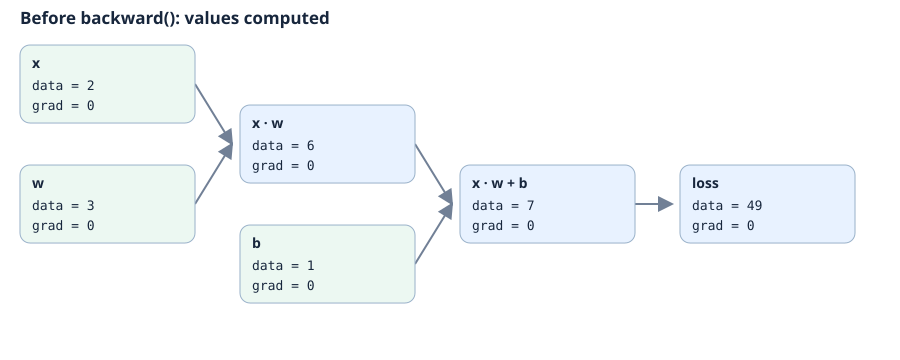

In [3]:
def draw_graph(title):
    """Draw the current Value objects without Graphviz."""
    nodes = [
        (x, 20, 45), (w, 20, 165), (product, 240, 105),
        (b, 240, 225), (sum_value, 460, 165), (loss, 680, 165),
    ]
    coords = {id(value): (left, top) for value, left, top in nodes}
    edges = [(x, product), (w, product), (product, sum_value),
             (b, sum_value), (sum_value, loss)]
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="900" height="360" viewBox="0 0 900 360" role="img">',
             '<defs><marker id="arrow" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 Z" fill="#718096"/></marker></defs>',
             f'<text x="20" y="24" font-family="sans-serif" font-size="17" font-weight="bold" fill="#17263c">{escape(title)}</text>']
    for source, target in edges:
        sx, sy = coords[id(source)]
        tx, ty = coords[id(target)]
        parts.append(f'<line x1="{sx+175}" y1="{sy+39}" x2="{tx-8}" y2="{ty+39}" stroke="#718096" stroke-width="2" marker-end="url(#arrow)"/>')
    for value, left, top in nodes:
        fill = "#e8f2ff" if value.prev else "#ecf8f2"
        parts.append(f'<rect x="{left}" y="{top}" width="175" height="78" rx="10" fill="{fill}" stroke="#9ab2ca"/>')
        parts.append(f'<text x="{left+12}" y="{top+23}" font-family="sans-serif" font-size="14" font-weight="bold" fill="#17263c">{escape(value.label)}</text>')
        parts.append(f'<text x="{left+12}" y="{top+45}" font-family="monospace" font-size="13" fill="#17263c">data = {value.data:.3g}</text>')
        parts.append(f'<text x="{left+12}" y="{top+65}" font-family="monospace" font-size="13" fill="#17263c">grad = {value.grad:.3g}</text>')
    parts.append('</svg>')
    display(SVG(''.join(parts)))

draw_graph("Before backward(): values computed")

## 3. Backward pass

For addition, the incoming gradient is passed to each input. For multiplication, each input's gradient is multiplied by the value of the other input. For the square, the local derivative is `2 · (x · w + b)`.

By hand: `d(loss)/d(sum) = 14`, then `d(loss)/dx = 14 · w = 42`, `d(loss)/dw = 14 · x = 28`, and `d(loss)/db = 14`.

x.grad = 42.0; w.grad = 28.0; b.grad = 14.0


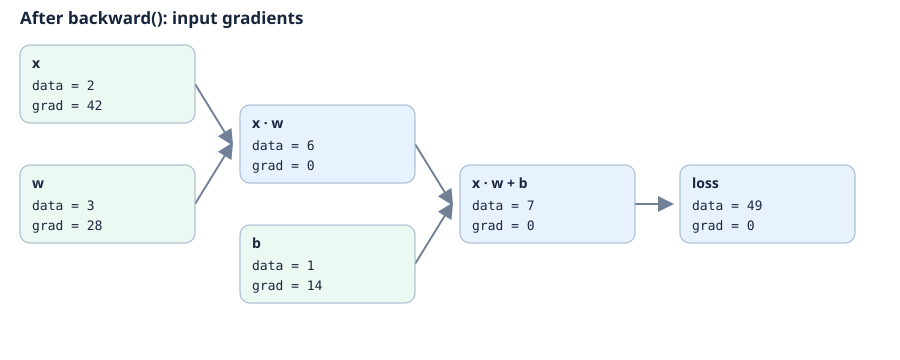

In [4]:
loss.backward()
print(f"x.grad = {x.grad}; w.grad = {w.grad}; b.grad = {b.grad}")
assert (x.grad, w.grad, b.grad) == (42.0, 28.0, 14.0)
draw_graph("After backward(): input gradients")

**Why are the intermediate nodes zero in the diagram?** The current `backward()` implementation clears their gradients after the pass. The gradients of the leaves `x`, `w`, and `b` are retained. The diagram therefore shows the state **after clearing**, rather than during gradient propagation.

## 4. A closer look at one callback

Create a separate graph and manually call the square operation's callback. This demonstrates one step; it does not call the full `backward()` method.

In [5]:
input_value = Value(7.0, label="input")
output_value = input_value ** 2
output_value.grad = 1.0
output_value._backward()
print(f"Incoming gradient: {output_value.grad}; input gradient: {input_value.grad}")
assert input_value.grad == 14.0

Incoming gradient: 1.0; input gradient: 14.0


## 5. Shared nodes and accumulation

A node such as `x` can participate in multiple operations. Its gradient is the sum of contributions from all paths. Calling `backward()` again on the same graph adds another contribution to the leaf gradient.

In [6]:
shared_x = Value(2.0)
shared_loss = shared_x * shared_x + shared_x
shared_loss.backward()
print(f"After the first pass: {shared_x.grad}")
assert shared_x.grad == 5.0
shared_loss.backward()
print(f"After the second pass: {shared_x.grad}")
assert shared_x.grad == 10.0
# Explicitly reset parameter gradients before the next independent experiment.
shared_x.grad = 0.0

After the first pass: 5.0
After the second pass: 10.0


## 6. Numerical gradient check

Compare the autograd gradient to the approximation `(f(x + h) − f(x − h)) / (2h)` for the same function. This independently checks the derivative with respect to `x`.

In [7]:
def plain_loss(x_value):
    return (x_value * 3.0 + 1.0) ** 2

h = 1e-5
numerical_grad = (plain_loss(2.0 + h) - plain_loss(2.0 - h)) / (2 * h)
print(f"Numerical: {numerical_grad:.6f}; autograd: {x.grad:.6f}")
assert abs(numerical_grad - x.grad) < 1e-6

Numerical: 42.000000; autograd: 42.000000


## What to try next

Change `x`, `w`, and `b` at the beginning, update the expected values in the `assert` checks, and run the entire notebook again. Then replace the square with `tanh()` and compare the analytical derivative with the numerical one. Remember that leaf gradients accumulate when running backward again on the same graph.